# Caso de estudio 2: de datos curados a datos enriquecidos

**Equipo 6:** Juan Pablo Esteva, Bruno Fidalgo, Ivan Lomando y Francisco Von Sanden

**Cómo reproducir**

1. Ejecutar antes `02_curacion_controles.ipynb`, que genera `data/curated/pedidos.parquet` e `items.parquet`. Este notebook parte de ahí y no lee los CSV crudos.
2. Las capas externas se descargan solas la primera vez en `data/external/` (no se suben al repositorio):
   - Límites municipales de Brasil: `geojs-100-mun.json` de https://github.com/tbrugz/geodata-br, derivados de la malla municipal del IBGE (5.564 municipios). Licencia Creative Commons CC0 1.0 (dominio público).
   - Sedes municipales, capitales y regiones: `municipios.csv` y `estados.csv` de https://github.com/kelvins/municipios-brasileiros (licencia MIT, datos del IBGE).
3. Ejecutar todas las celdas en orden desde `notebooks/`. En Colab, las mismas instrucciones que el notebook 02.

**Salidas:** `data/enriched/pedidos_enriquecidos.gpkg` (capas `pedidos` y `uf`), `data/enriched/pedidos_enriquecidos.parquet`, `reports/importancia_features.csv`, `reports/desafio_enriquecido.csv` y figuras en `reports/figs/`. `data/curated/` no se modifica.

In [1]:
import os
import sys
import urllib.request
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.metrics import roc_auc_score

sys.path.append("..")
from src.contratos import exigir, validar_enriquecido, exigir_enriquecido

RUTA_CURATED = "../data/curated/"
RUTA_EXTERNAL = "../data/external/"
RUTA_ENRICHED = "../data/enriched/"
RUTA_REPORTS = "../reports/"
RUTA_FIGS = "../reports/figs/"
for ruta in [RUTA_EXTERNAL, RUTA_ENRICHED, RUTA_FIGS]:
    os.makedirs(ruta, exist_ok=True)

CRS_GEOGRAFICO = "EPSG:4326"
CRS_METRICO = "EPSG:5880"
CRS_AREA = "ESRI:102033"
SEMILLA = 42

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

## 1. Punto de partida

Cargamos el producto curado del Caso 1 y volvemos a correr su contrato. Desde la entrega del Caso 1 el dataset no cambió: es el mismo `pedidos.parquet` (99.441 filas, una por pedido) e `items.parquet` (112.650 filas, una por ítem).

In [2]:
pedidos = pd.read_parquet(RUTA_CURATED + "pedidos.parquet")
items = pd.read_parquet(RUTA_CURATED + "items.parquet")
exigir(pedidos, items, n_orders=99441)

Contrato OK: 99441 pedidos y 112650 ítems


### Preguntas del Caso 2

Continúan las del Caso 1 (P1: atrasos por estado; P2: reseña y demora):

- **Q1.** ¿La distancia entre vendedor y cliente explica las diferencias regionales en el porcentaje de entregas tarde que encontramos en P1, o queda un efecto geográfico a igual distancia?
- **Q2.** ¿Qué variables disponibles al momento de la compra anticipan un atraso, y cuánto agregan las variables espaciales a las tabulares?
- **Q3.** ¿En qué estados y municipios el atraso es mayor que el que explican las variables tabulares, y conviene priorizarlos para revisar la logística?

### Predicción (registrada el 22/11/2026, antes de crear features)

**Variables con más potencial de derivación.** Las fechas: el plazo prometido (fecha estimada menos compra) debería explicar buena parte de los atrasos, porque un plazo corto deja menos margen. También precio y flete: el flete relativo al precio mide cuánto pesa el envío en la compra. Esperamos poco de la hora o el día de compra.

**Información geográfica.** La distancia entre vendedor y cliente, porque la mayoría de los vendedores está en SP. Esperamos que explique la diferencia entre el nordeste y el sudeste que vimos en P1, y que el porcentaje de atrasos deje de depender de la región cuando se compara a igual distancia.

El contraste está en la sección 6.

## 2. Capas externas y coordenadas

Las coordenadas de clientes y vendedores salen del Caso 1 (D17): mediana de `geolocation` por prefijo de CEP, sin los puntos fuera de Brasil. No son direcciones: representan la zona del prefijo, con 50% de los puntos a menos de 0,5 km de la mediana y 99% a menos de 9,8 km. 279 clientes y 7 vendedores no tienen coordenadas.

In [3]:
CAPAS = {
    "municipios.geojson": "https://raw.githubusercontent.com/tbrugz/geodata-br/master/geojson/geojs-100-mun.json",
    "municipios_sedes.csv": "https://raw.githubusercontent.com/kelvins/municipios-brasileiros/main/csv/municipios.csv",
    "estados.csv": "https://raw.githubusercontent.com/kelvins/municipios-brasileiros/main/csv/estados.csv",
}
for archivo, url in CAPAS.items():
    if not os.path.exists(RUTA_EXTERNAL + archivo):
        urllib.request.urlretrieve(url, RUTA_EXTERNAL + archivo)
    print(f"{archivo:22s} {os.path.getsize(RUTA_EXTERNAL + archivo) / 1e6:6.1f} MB")

municipios = gpd.read_file(RUTA_EXTERNAL + "municipios.geojson")[["id", "name", "geometry"]]
municipios.columns = ["cod_municipio", "municipio", "geometry"]
sedes = pd.read_csv(RUTA_EXTERNAL + "municipios_sedes.csv", dtype={"codigo_ibge": str, "codigo_uf": str})
estados = pd.read_csv(RUTA_EXTERNAL + "estados.csv", dtype={"codigo_uf": str}, encoding="utf-8-sig")
print("CRS de la capa municipal:", municipios.crs, "| municipios:", len(municipios), "| sedes:", len(sedes))
print("Geometrías inválidas:", (~municipios.is_valid).sum())

municipios.geojson       22.5 MB
municipios_sedes.csv      0.4 MB
estados.csv               0.0 MB


CRS de la capa municipal: EPSG:4326 | municipios: 5564 | sedes: 5571
Geometrías inválidas: 46


In [4]:
municipios["geometry"] = municipios.geometry.make_valid()
municipios["codigo_uf"] = municipios["cod_municipio"].str[:2]
municipios = municipios.merge(estados[["codigo_uf", "uf", "regiao"]], on="codigo_uf", how="left", validate="many_to_one")
municipios = municipios.rename(columns={"uf": "uf_municipio"})
municipios["area_km2"] = municipios.to_crs(CRS_AREA).area / 1e6
capitales = sedes[sedes["capital"] == 1].merge(estados[["codigo_uf", "uf"]], on="codigo_uf", validate="one_to_one")
capitales = gpd.GeoDataFrame(capitales[["uf", "nome", "codigo_ibge"]], geometry=gpd.points_from_xy(capitales["longitude"], capitales["latitude"]),
                             crs=CRS_GEOGRAFICO).to_crs(CRS_METRICO)
print("Geometrías inválidas después de make_valid:", (~municipios.is_valid).sum())
print("Municipios sin UF:", municipios["uf_municipio"].isna().sum(), "| capitales:", len(capitales))
print("Sedes que no están en la capa de límites:", (~sedes["codigo_ibge"].isin(municipios["cod_municipio"])).sum())
municipios["area_km2"].describe().round(1)

Geometrías inválidas después de make_valid: 0
Municipios sin UF: 0 | capitales: 27
Sedes que no están en la capa de límites: 7


count      5564.0
mean       1528.1
std        5622.9
min           2.5
25%         203.9
50%         415.3
75%        1027.9
max      159522.2
Name: area_km2, dtype: float64

**CRS.** La capa viene en EPSG:4326 (grados). Las distancias se calculan en **EPSG:5880** (SIRGAS 2000 / Brazil Polyconic, en metros), pensado para todo Brasil, y las áreas en **ESRI:102033** (South America Albers Equal Area), que conserva áreas. Nunca se calcula en grados; uno de los controles de la sección 7 falla si las distancias parecen estar en grados.

**Calidad de la capa.** 46 polígonos venían inválidos (anillos que se cruzan) y se reparan con `make_valid`; sin eso, el spatial join dejaba sin municipio a 8.579 pedidos, sobre todo de RJ y ES. La capa tiene 5.564 municipios: es una malla anterior a la creación de los últimos 6, así que esos municipios quedan dentro de los que les dieron origen.

## 3. Pipeline de enriquecimiento

Todo el enriquecimiento es una función que recibe el producto curado y las capas. Así el desafío de la sección 8 puede correr el pipeline completo con datos o capas modificados.

In [5]:
BLACK_FRIDAYS = pd.to_datetime(["2016-11-25", "2017-11-24", "2018-11-23"])


def puntos(df, lat, lng, crs=CRS_GEOGRAFICO):
    geometria = gpd.points_from_xy(df[lng], df[lat])
    geometria = np.where(df[lat].notna(), geometria, None)
    return gpd.GeoDataFrame(df, geometry=list(geometria), crs=crs)


def enriquecer(pedidos, items, municipios, capitales, crs_metrico=CRS_METRICO):
    df = pedidos.copy()

    con_items = df["n_items"] > 0
    df["ratio_flete_precio"] = (df["total_flete"] / df["total_precio"]).where(con_items)
    df["pago_sobre_items"] = (df["total_pagado"] / (df["total_precio"] + df["total_flete"])).where(con_items)
    df["precio_medio_item"] = (df["total_precio"] / df["n_items"]).where(con_items)

    compra = df["order_purchase_timestamp"]
    df["dias_prometidos"] = (df["order_estimated_delivery_date"] - compra).dt.total_seconds() / 86400
    df["horas_aprobacion"] = (df["order_approved_at"] - compra).dt.total_seconds() / 3600
    df["dia_semana"] = compra.dt.dayofweek.astype("int64")
    df["hora_compra"] = compra.dt.hour.astype("int64")
    df["mes_compra"] = compra.dt.month.astype("int64")
    df["dias_a_black_friday"] = np.abs(compra.values[:, None] - BLACK_FRIDAYS.values[None, :]).min(axis=1).astype("timedelta64[D]").astype(int)
    df = df.sort_values("order_purchase_timestamp")
    df["compras_previas"] = df.groupby("customer_unique_id").cumcount()
    df = df.sort_index()

    peso = items.groupby("order_id")["product_weight_g"].agg(lambda x: x.sum() if x.notna().all() else np.nan) / 1000
    df["peso_total_kg"] = df["order_id"].map(peso)
    df["tamano_pedido"] = pd.qcut(df["total_precio"].where(con_items), 4, labels=["chico", "mediano", "grande", "muy grande"])

    clientes = puntos(df[["order_id", "cliente_lat", "cliente_lng"]], "cliente_lat", "cliente_lng").to_crs(crs_metrico)
    vendedores = puntos(items[["order_id", "seller_state", "vendedor_lat", "vendedor_lng"]], "vendedor_lat", "vendedor_lng").to_crs(crs_metrico)
    cliente_de_item = clientes.set_index("order_id").geometry.reindex(vendedores["order_id"]).values
    vendedores["distancia_km"] = vendedores.geometry.distance(gpd.GeoSeries(cliente_de_item, crs=crs_metrico, index=vendedores.index)) / 1000
    df["distancia_vendedor_km"] = df["order_id"].map(vendedores.groupby("order_id")["distancia_km"].max())
    estado_vendedor = items.groupby("order_id")["seller_state"].agg(lambda x: set(x))
    df["mismo_estado"] = pd.array([
        pd.NA if not isinstance(s, set) else (uf in s and len(s) == 1)
        for uf, s in zip(df["customer_state"], df["order_id"].map(estado_vendedor))], dtype="boolean")

    capa = municipios.to_crs(crs_metrico)
    con_coord = clientes[clientes.geometry.notna()]
    unidos = gpd.sjoin(con_coord, capa[["cod_municipio", "municipio", "uf_municipio", "regiao", "area_km2", "geometry"]],
                       how="left", predicate="within").drop(columns="index_right")
    unidos = unidos[~unidos["order_id"].duplicated()]
    sin_match = unidos.loc[unidos["cod_municipio"].isna(), "order_id"]
    if len(sin_match):
        cercanos = gpd.sjoin_nearest(con_coord[con_coord["order_id"].isin(sin_match)],
                                     capa[["cod_municipio", "municipio", "uf_municipio", "regiao", "area_km2", "geometry"]],
                                     how="left", max_distance=5000).drop(columns="index_right")
        cercanos = cercanos[~cercanos["order_id"].duplicated()].set_index("order_id")
        unidos = unidos.set_index("order_id")
        unidos.update(cercanos[["cod_municipio", "municipio", "uf_municipio", "regiao", "area_km2"]])
        unidos = unidos.reset_index()
    unidos["municipio_por_cercania"] = unidos["order_id"].isin(sin_match)
    df = df.merge(pd.DataFrame(unidos.drop(columns="geometry")).drop(columns=["cliente_lat", "cliente_lng"]),
                  on="order_id", how="left", validate="one_to_one")
    df["municipio_por_cercania"] = df["municipio_por_cercania"].astype("boolean").fillna(False).astype(bool)
    df["uf_distinta"] = df["uf_municipio"].notna() & (df["uf_municipio"] != df["customer_state"])

    capital_uf = capitales.set_index("uf").to_crs(crs_metrico).geometry
    destino = gpd.GeoSeries(capital_uf.reindex(df["customer_state"]).values, crs=crs_metrico, index=df.index)
    df["distancia_capital_km"] = clientes.geometry.distance(destino) / 1000
    df["es_capital"] = pd.array(df["cod_municipio"].isin(capitales["codigo_ibge"]), dtype="boolean")
    df.loc[df["cod_municipio"].isna(), "es_capital"] = pd.NA

    clientes_mun = df.groupby("cod_municipio")["customer_unique_id"].nunique()
    df["densidad_clientes_km2"] = df["cod_municipio"].map(clientes_mun) / df["area_km2"]

    rangos = {
        "distancia_vendedor_km": df["distancia_vendedor_km"].rank(pct=True),
        "peso_total_kg": df["peso_total_kg"].rank(pct=True),
        "varios_vendedores": (df["n_vendedores"] > 1).astype(float).where(con_items),
    }
    df["indice_envio_dificil"] = pd.DataFrame(rangos).mean(axis=1, skipna=False)

    df["region"] = df["customer_state"].map(estados.set_index("uf")["regiao"])
    return puntos(df, "cliente_lat", "cliente_lng")


enriquecido = enriquecer(pedidos, items, municipios, capitales)
print(enriquecido.shape, enriquecido.crs)
print("Asignados por cercanía:", enriquecido["municipio_por_cercania"].sum(),
      "| sin municipio:", enriquecido["cod_municipio"].isna().sum(),
      "| municipio de otra UF:", enriquecido["uf_distinta"].sum())

(99441, 63) EPSG:4326
Asignados por cercanía: 48 | sin municipio: 279 | municipio de otra UF: 34


**Interpretación:** de los 99.162 pedidos con coordenadas, todos recibieron un municipio: 99.114 por estar dentro del polígono y 48 por cercanía (a menos de 5 km), porque el centro de su prefijo cae sobre la costa o en un borde que la malla simplificada no cubre. Los 279 pedidos sin municipio son exactamente los clientes sin coordenadas del Caso 1. En 34 pedidos (0,03%) el municipio asignado es de otra UF que la declarada por el cliente: son prefijos de CEP en el límite entre estados. **Decisión:** se conservan con el indicador `uf_distinta`, y para los análisis por estado se usa la UF declarada (`customer_state`), no la del polígono. **Qué no podemos concluir:** el municipio real de cada cliente; solo el del centro de su prefijo.

## 4. Feature engineering

### 4.1 Features creadas

| Tipo | Feature | Qué captura que las originales no | Construcción |
|---|---|---|---|
| Ratio | `ratio_flete_precio` | cuánto pesa el envío respecto de lo comprado | `total_flete / total_precio` |
| Ratio | `pago_sobre_items` | recargo por cuotas o vouchers | `total_pagado / (total_precio + total_flete)` |
| Ratio | `precio_medio_item` | precio típico del pedido, independiente de la cantidad | `total_precio / n_items` |
| Temporal | `dias_prometidos` | margen que la plataforma se dio para entregar | estimada − compra, en días |
| Temporal | `horas_aprobacion` | demora del pago | aprobación − compra, en horas |
| Temporal | `dia_semana`, `hora_compra`, `mes_compra` | estacionalidad semanal, diaria y anual | componentes de la fecha de compra |
| Temporal | `dias_a_black_friday` | cercanía al pico de demanda | días al Black Friday más cercano (2016-2018) |
| Temporal | `compras_previas` | antigüedad del cliente | pedidos anteriores del mismo `customer_unique_id` |
| Compuesta | `peso_total_kg` | carga física del pedido | suma del peso de los productos (nulo si falta alguno) |
| Compuesta | `tamano_pedido` | categoría de valor del pedido | cuartiles de `total_precio` |
| Compuesta | `indice_envio_dificil` | dificultad logística en un solo número | promedio de los percentiles de distancia y peso, y de tener varios vendedores (0 a 1) |
| Espacial | `distancia_vendedor_km` | separación física entre origen y destino | distancia en EPSG:5880; con varios vendedores, la mayor |
| Espacial | `mismo_estado` | envío dentro del mismo estado | UF del cliente igual a la de todos sus vendedores |
| Espacial | `distancia_capital_km` | lejanía del centro logístico del estado | distancia a la capital de su UF, EPSG:5880 |
| Espacial | `es_capital`, `densidad_clientes_km2`, `region` | contexto urbano y regional | spatial join con municipios y área en ESRI:102033 |

Todas usan información disponible **al momento de la compra** (o de la aprobación). No se usan fechas de entrega para no filtrar el resultado en las features que se evalúan contra `llego_tarde`.

### 4.2 Distribuciones y valores inesperados

In [6]:
FEATURES = ["ratio_flete_precio", "pago_sobre_items", "precio_medio_item", "total_precio", "n_items", "dias_prometidos",
            "horas_aprobacion", "dia_semana", "hora_compra", "mes_compra", "dias_a_black_friday", "compras_previas",
            "peso_total_kg", "indice_envio_dificil", "distancia_vendedor_km", "distancia_capital_km", "densidad_clientes_km2"]
resumen = enriquecido[FEATURES].describe(percentiles=[0.01, 0.5, 0.99]).T
resumen["nulos"] = enriquecido[FEATURES].isna().sum()
q1, q3 = enriquecido[FEATURES].quantile(0.25), enriquecido[FEATURES].quantile(0.75)
resumen["pct_outliers_iqr"] = ((enriquecido[FEATURES] < q1 - 1.5 * (q3 - q1)) | (enriquecido[FEATURES] > q3 + 1.5 * (q3 - q1))).mean() * 100
resumen.round(2)

,count,mean,std,min,1%,50%,99%,max,nulos,pct_outliers_iqr
ratio_flete_precio,98666.0,0.31,0.31,0.00,0.02,0.22,1.46,21.45,775,6.60
pago_sobre_items,98666.0,1.00,0.01,0.00,1.00,1.00,1.00,1.41,775,19.73
precio_medio_item,98666.0,125.92,190.99,0.85,10.99,79.00,899.99,6735.00,775,7.64
total_precio,99441.0,136.68,210.17,0.00,7.90,85.00,998.00,13440.00,0,7.95
n_items,99441.0,1.13,0.55,0.00,1.00,1.00,3.00,21.00,0,10.64
dias_prometidos,99441.0,23.77,8.83,1.65,6.02,23.24,50.42,155.14,0,2.57
horas_aprobacion,99281.0,10.42,26.04,0.00,0.00,0.34,90.17,4509.18,160,9.19
dia_semana,99441.0,2.76,1.97,0.00,0.00,3.00,6.00,6.00,0,0.00
hora_compra,99441.0,14.77,5.33,0.00,0.00,15.00,23.00,23.00,0,0.00
mes_compra,99441.0,6.03,3.23,1.00,1.00,6.00,12.00,12.00,0,0.00


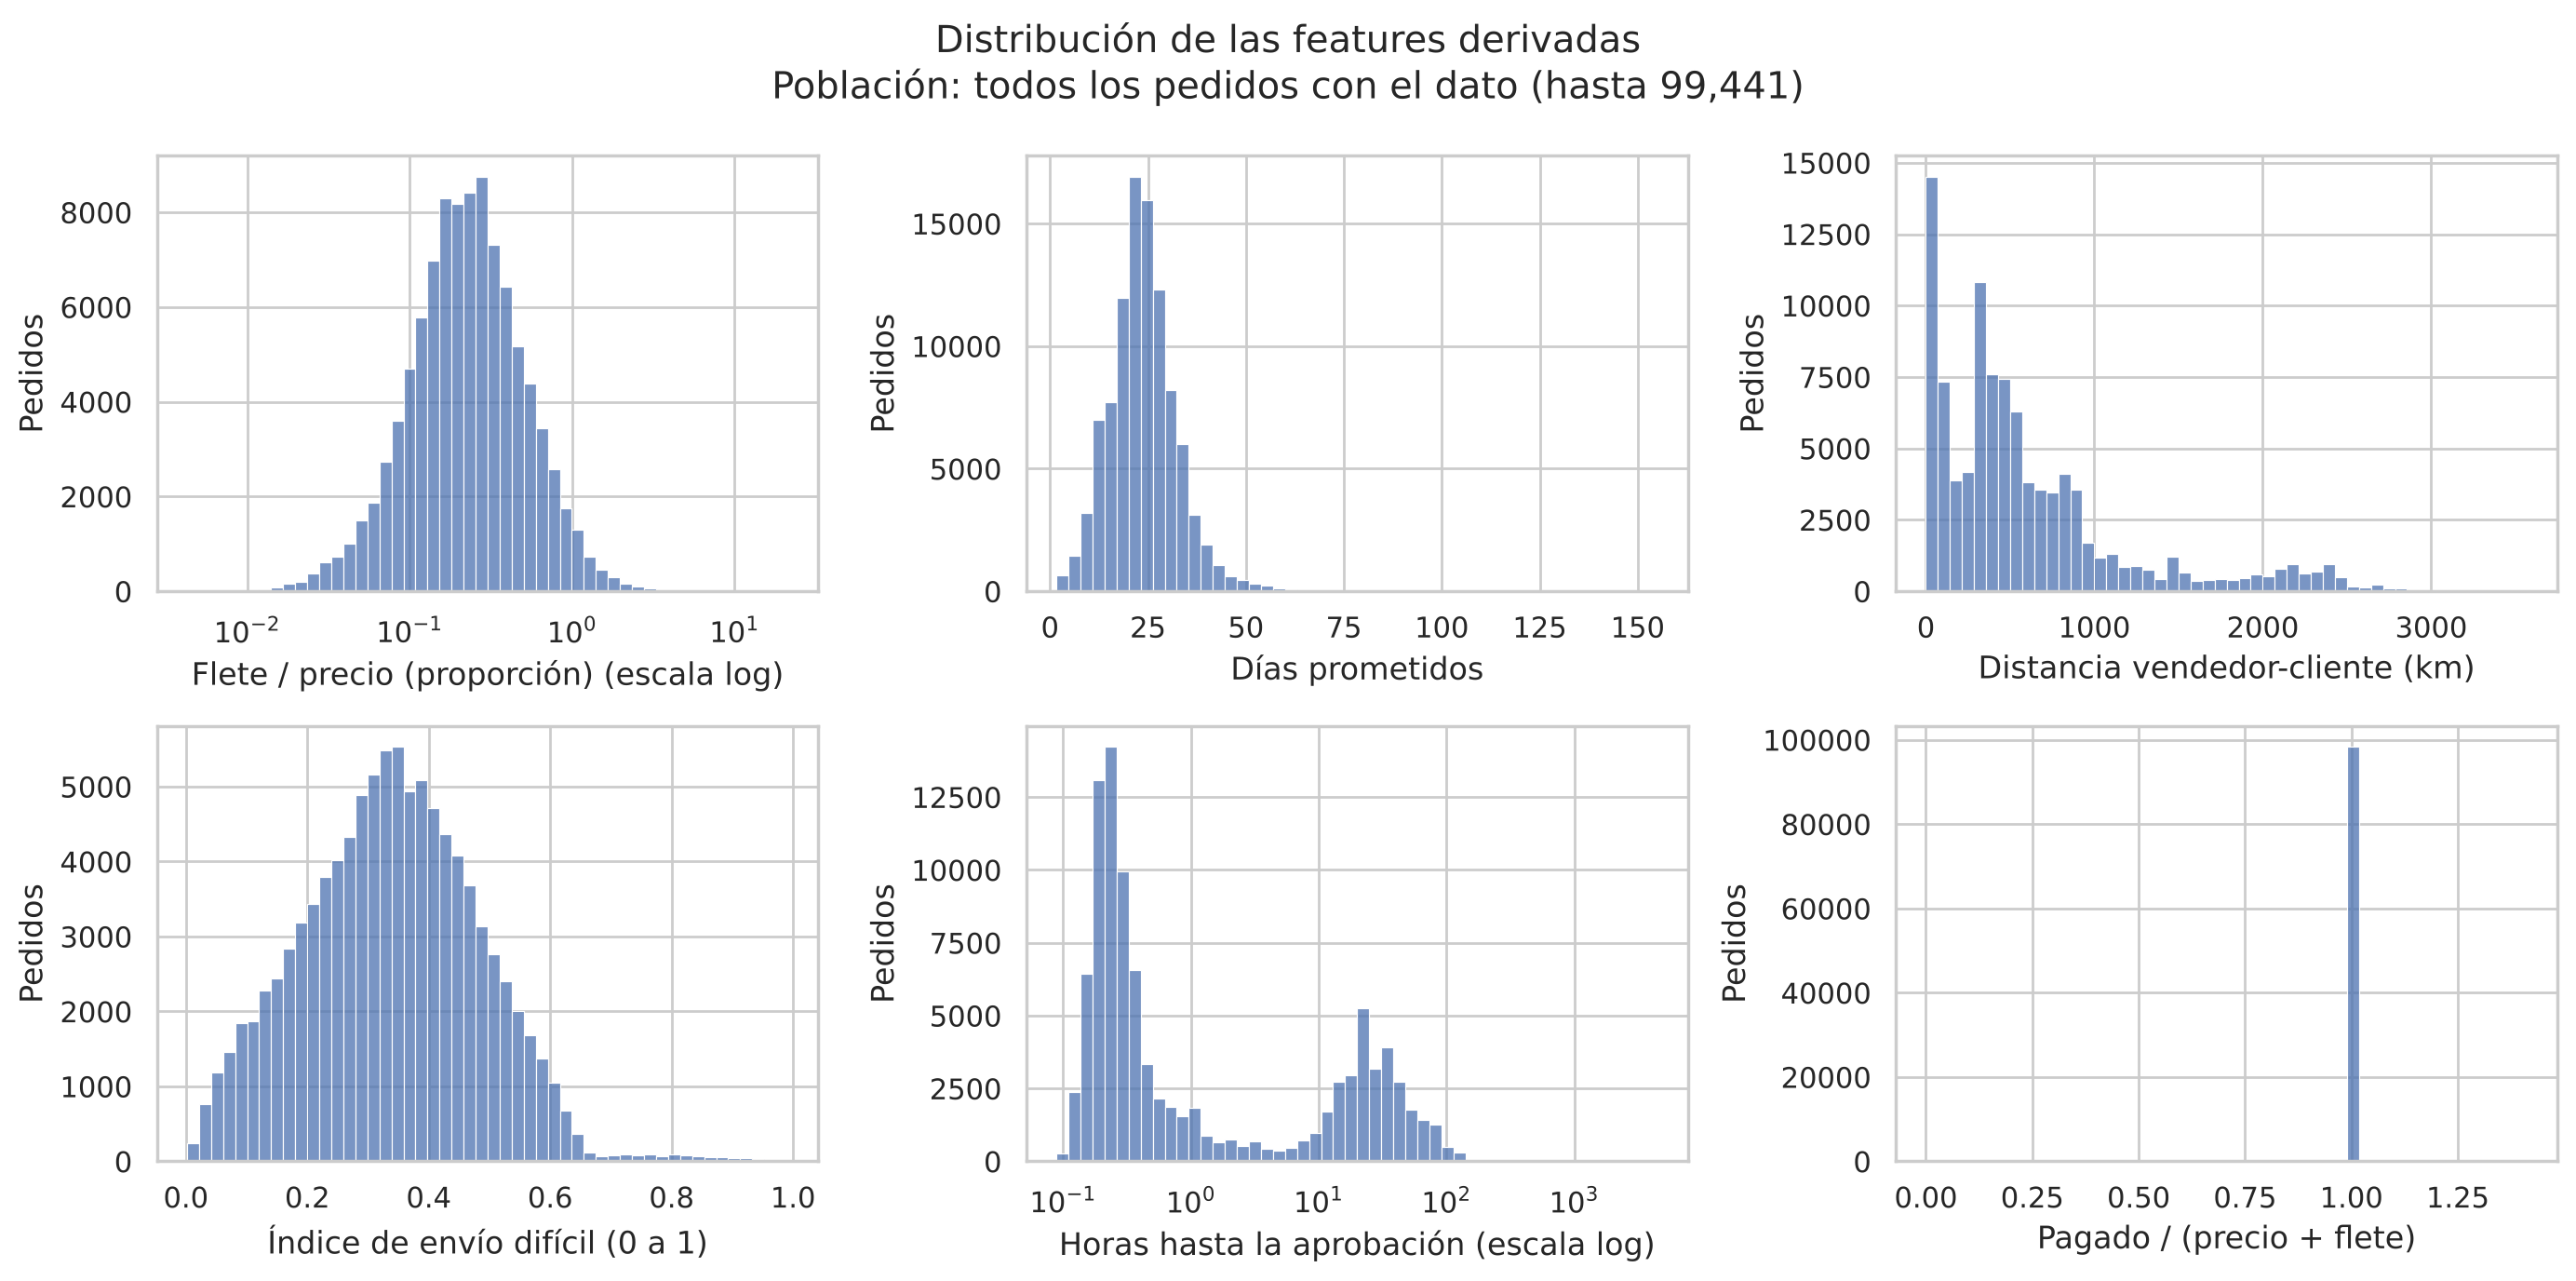

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
graficos = [("ratio_flete_precio", "Flete / precio (proporción)", True), ("dias_prometidos", "Días prometidos", False),
            ("distancia_vendedor_km", "Distancia vendedor-cliente (km)", False), ("indice_envio_dificil", "Índice de envío difícil (0 a 1)", False),
            ("horas_aprobacion", "Horas hasta la aprobación", True), ("pago_sobre_items", "Pagado / (precio + flete)", False)]
for ax, (col, etiqueta, log) in zip(axes.flat, graficos):
    datos = enriquecido[col].dropna()
    sns.histplot(datos[datos > 0] if log else datos, bins=50, log_scale=log, ax=ax)
    ax.set_xlabel(etiqueta + (" (escala log)" if log else ""))
    ax.set_ylabel("Pedidos")
fig.suptitle(f"Distribución de las features derivadas\nPoblación: todos los pedidos con el dato (hasta {len(enriquecido):,})")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "c2_01_distribuciones.png", dpi=150)
plt.show()

**Interpretación:**

- `ratio_flete_precio` tiene mediana 0,22 (el flete es el 22% del precio) y el 99% de los pedidos está por debajo de 1,46. El máximo, 21,4, corresponde a productos baratos con flete caro: es un evento poco frecuente, no un error, y se mantiene.
- `pago_sobre_items` vale 1,00 en más del 99% de los pedidos. El 19,7% de "outliers" por IQR es un artefacto de un IQR casi nulo, no una cola real: la feature casi no tiene variación.
- `dias_prometidos` va de 1,6 a 155 días, con mediana 23,2.
- `horas_aprobacion` es bimodal: la mayoría se aprueba en minutos y otro grupo tarda alrededor de un día, lo que coincide con el pago con tarjeta frente al boleto. El máximo, 4.509 horas (188 días), es raro y se conserva.
- `distancia_vendedor_km` tiene mediana 436 km y llega a 3.570 km. El pico cerca de 0 corresponde a vendedor y cliente en la misma ciudad.
- `indice_envio_dificil` cubre todo el rango de 0 a 1, con mediana 0,34. Se usó el percentil, no los valores crudos, para que distancia y peso pesen lo mismo.

**Decisión:** ninguna feature se recorta; `pago_sobre_items` queda como candidata a descarte.

### 4.3 Importancia de las features

Variable de interés: `llego_tarde` (P1), sobre pedidos `delivered` con fecha. Dos métodos:

1. **Información mutua** con `llego_tarde`: mide dependencia de cualquier forma, de a una variable por vez.
2. **Importancia por permutación** en un Random Forest: cuánto cae el AUC en un conjunto de prueba al desordenar cada variable, teniendo en cuenta las demás.

Agregamos la correlación de Spearman con `review_score` (P2) como referencia.

In [8]:
MODELO = ["ratio_flete_precio", "pago_sobre_items", "precio_medio_item", "total_precio", "n_items", "dias_prometidos",
          "horas_aprobacion", "dia_semana", "hora_compra", "mes_compra", "dias_a_black_friday", "compras_previas",
          "peso_total_kg", "indice_envio_dificil", "distancia_vendedor_km", "mismo_estado", "distancia_capital_km",
          "es_capital", "densidad_clientes_km2"]
base = enriquecido[enriquecido["llego_tarde"].notna()].copy()
X = base[MODELO].astype(float)
X = X.fillna(X.median())
y = base["llego_tarde"].astype(int)
print("Población:", len(base), "pedidos;", round(y.mean() * 100, 2), "% tarde")

mi = mutual_info_classif(X, y, discrete_features=[c in ["dia_semana", "hora_compra", "mes_compra", "n_items", "mismo_estado", "es_capital"] for c in MODELO],
                         random_state=SEMILLA)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
bosque = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=50, class_weight="balanced",
                                n_jobs=-1, random_state=SEMILLA).fit(X_train, y_train)
auc = roc_auc_score(y_test, bosque.predict_proba(X_test)[:, 1])
perm = permutation_importance(bosque, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEMILLA, n_jobs=-1)

spearman = base[MODELO].astype(float).corrwith(base["review_score"], method="spearman")
importancia = pd.DataFrame({"info_mutua": mi, "permutacion_auc": perm.importances_mean, "perm_desvio": perm.importances_std,
                            "spearman_review": spearman.values}, index=MODELO)
importancia["rank_mi"] = importancia["info_mutua"].rank(ascending=False).astype(int)
importancia["rank_perm"] = importancia["permutacion_auc"].rank(ascending=False).astype(int)
importancia = importancia.sort_values("permutacion_auc", ascending=False)
importancia.to_csv(RUTA_REPORTS + "importancia_features.csv")
print(f"AUC del Random Forest en prueba: {auc:.3f}")
importancia.round(4)

Población: 96470 pedidos; 6.77 % tarde


AUC del Random Forest en prueba: 0.781


,info_mutua,permutacion_auc,perm_desvio,spearman_review,rank_mi,rank_perm
mes_compra,0.0126,0.0953,0.0060,0.0340,3,1
dias_prometidos,0.0033,0.0514,0.0008,-0.0556,10,2
dias_a_black_friday,0.0099,0.0503,0.0029,0.0452,5,3
distancia_vendedor_km,0.0049,0.0323,0.0028,-0.0673,9,4
mismo_estado,0.0024,0.0234,0.0021,0.0619,11,5
densidad_clientes_km2,0.0127,0.0114,0.0011,0.0051,2,6
distancia_capital_km,0.0119,0.0101,0.0004,0.0140,4,7
horas_aprobacion,0.0014,0.0084,0.0011,-0.0072,13,8
indice_envio_dificil,0.0018,0.0030,0.0010,-0.0793,12,9
peso_total_kg,0.0010,0.0019,0.0005,-0.0333,14,10


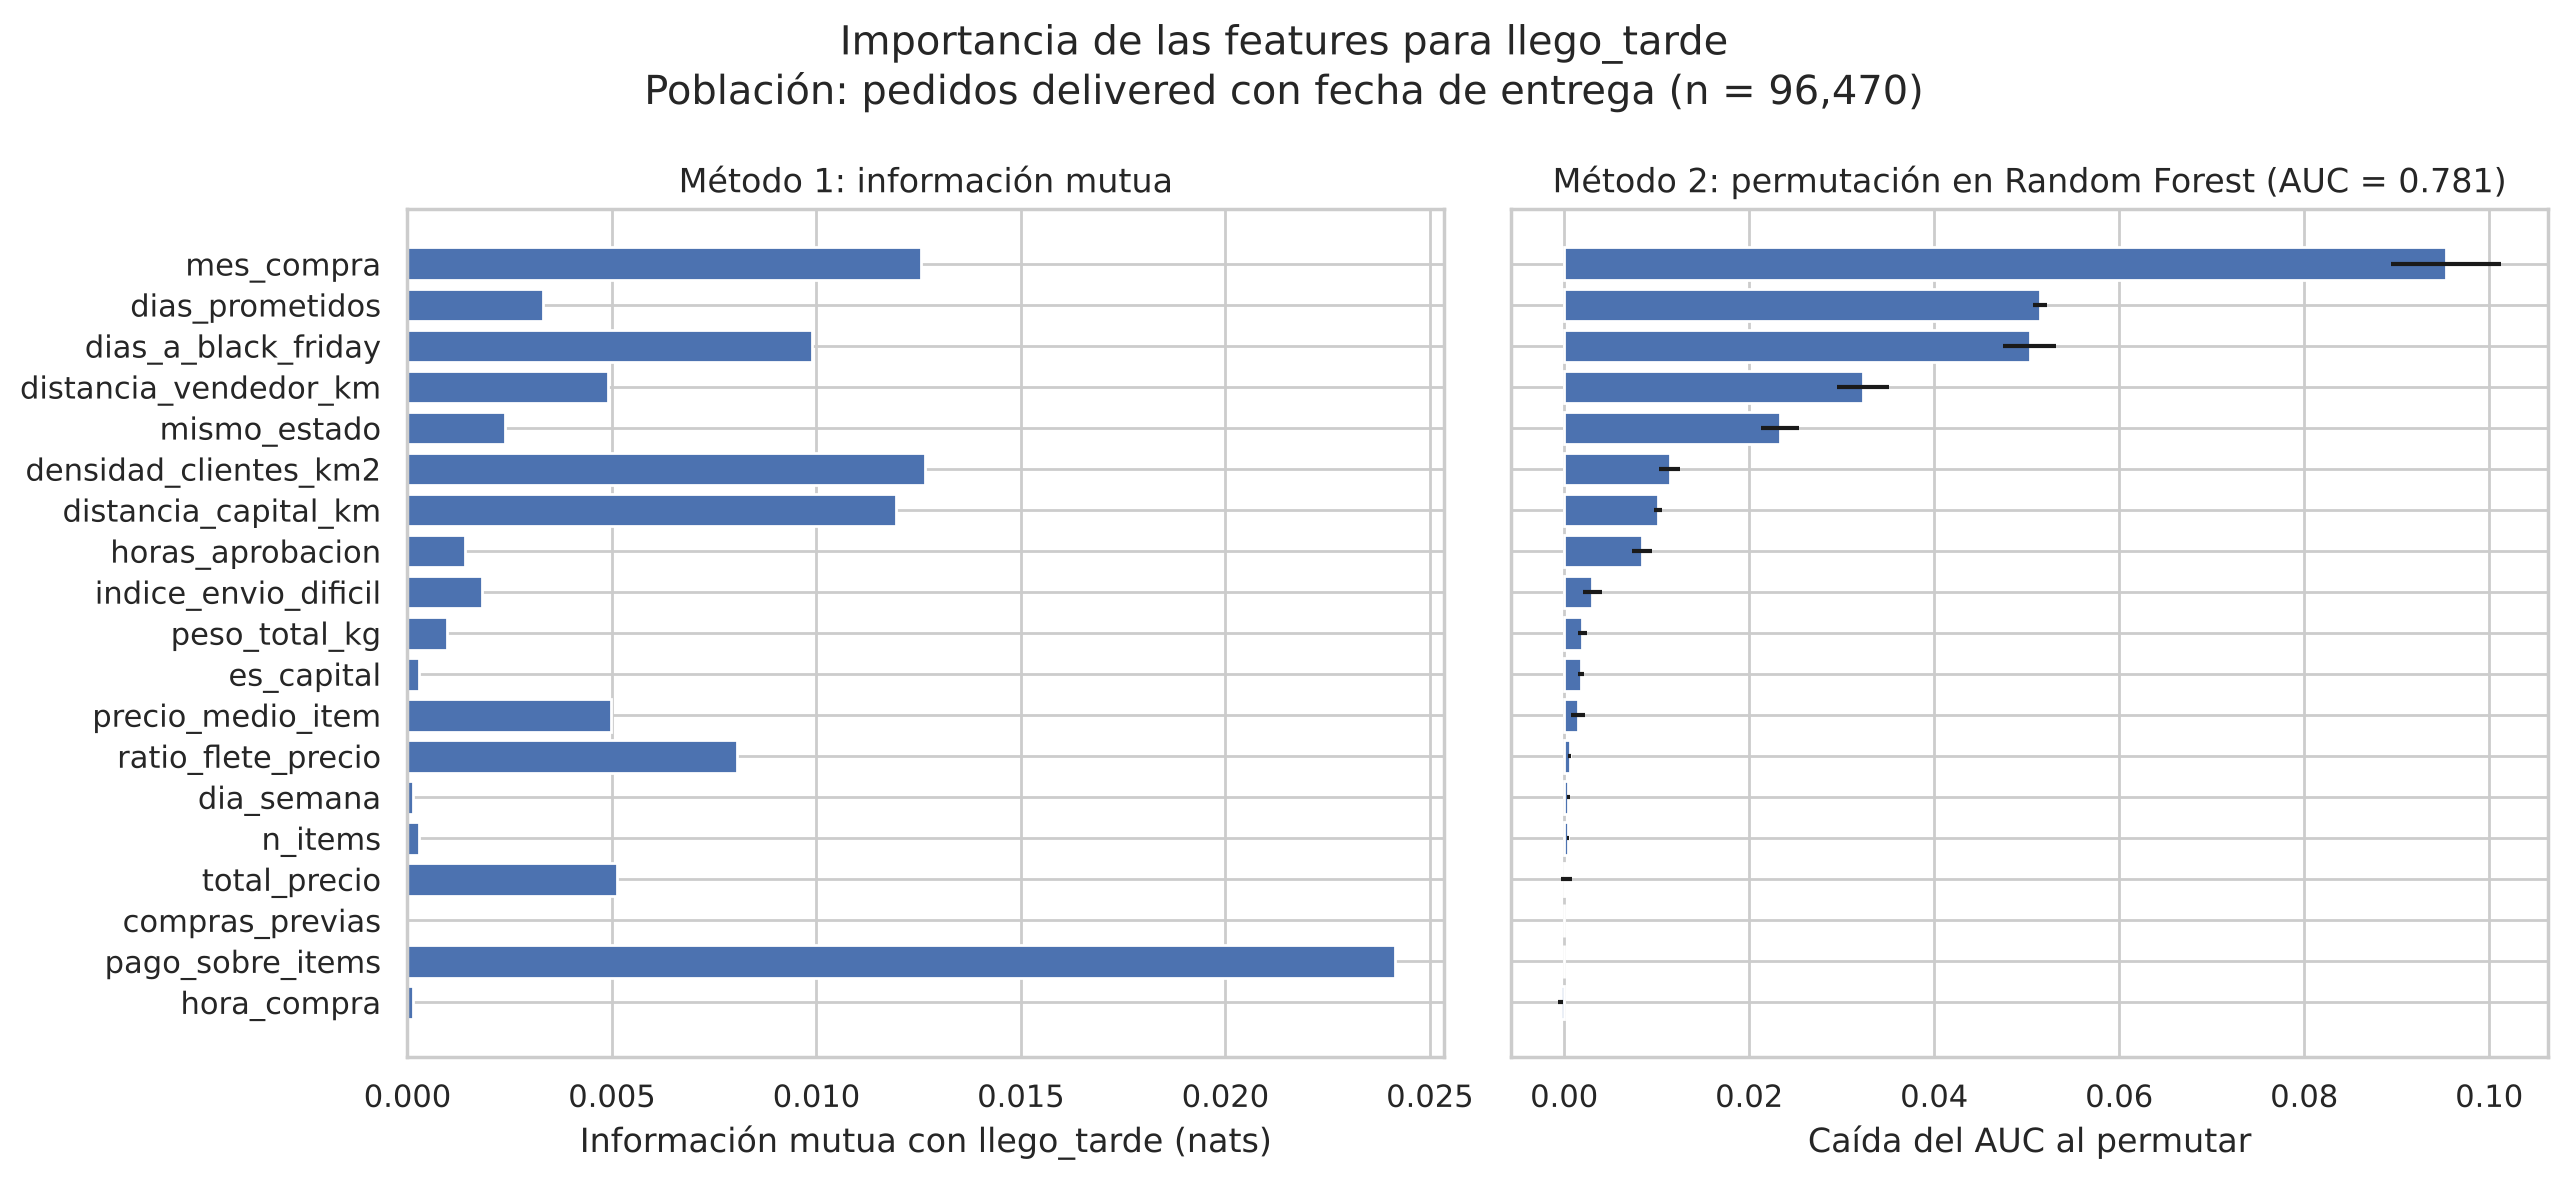

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
orden = importancia.index
axes[0].barh(orden, importancia["info_mutua"])
axes[0].set_xlabel("Información mutua con llego_tarde (nats)")
axes[0].set_title("Método 1: información mutua")
axes[1].barh(orden, importancia["permutacion_auc"], xerr=importancia["perm_desvio"])
axes[1].set_xlabel("Caída del AUC al permutar")
axes[1].set_title(f"Método 2: permutación en Random Forest (AUC = {auc:.3f})")
axes[0].invert_yaxis()
fig.suptitle(f"Importancia de las features para llego_tarde\nPoblación: pedidos delivered con fecha de entrega (n = {len(base):,})")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "c2_02_importancia.png", dpi=150)
plt.show()

**Interpretación:** el Random Forest alcanza un AUC de 0,781 en el 25% de prueba. Los dos métodos coinciden en lo que no aporta (`hora_compra`, `dia_semana`, `compras_previas`, `n_items`) y en que `mes_compra` y `dias_a_black_friday` están arriba (1.ª y 3.ª por permutación, 3.ª y 5.ª por información mutua). Las discrepancias principales son cuatro:

- **`dias_prometidos` y `distancia_vendedor_km`** son 2.ª y 4.ª por permutación, pero 10.ª y 9.ª por información mutua. La información mutua mira cada variable sola, mientras que el plazo probablemente importa en combinación con la distancia (un plazo corto es un problema si el envío es largo), y esa interacción solo la ve el bosque.

- **`pago_sobre_items`** es la primera por información mutua y la última por permutación. Es casi constante: el estimador de información mutua por vecinos cercanos se distorsiona con tantos valores repetidos, y el bosque, que evalúa en conjunto, no le encuentra uso.
- **`densidad_clientes_km2`, `distancia_capital_km` y `ratio_flete_precio`** tienen información mutua alta y permutación baja. Cada una sola informa (la información mutua mira una variable por vez), pero lo que aportan ya está en otras: el flete se cobra según distancia y peso, y la densidad separa capitales del interior igual que la UF. Al permutar una, el modelo usa sus sustitutas.
- **`mes_compra`** es la primera por permutación. Con solo 20 meses de datos útiles, el mes identifica períodos puntuales (picos de demanda como noviembre de 2017) más que una estacionalidad que se repita.

La correlación con `review_score` es débil para todas (|ρ| ≤ 0,11); la mayor es `n_items` (−0,11): los pedidos con más ítems reciben peor puntaje.

In [10]:
ESPACIALES = ["distancia_vendedor_km", "mismo_estado", "distancia_capital_km",
              "es_capital", "densidad_clientes_km2", "indice_envio_dificil"]
SIN_ESPACIALES = [c for c in MODELO if c not in ESPACIALES]


def auc_cv(cols):
    Xc = base[cols].astype(float)
    Xc = Xc.fillna(Xc.median())
    rf = RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=50, n_jobs=-1, random_state=SEMILLA)
    return roc_auc_score(y, cross_val_predict(rf, Xc, y, cv=5, method="predict_proba")[:, 1])


print("Validación cruzada de 5 particiones. Con espaciales:", round(auc_cv(MODELO), 3), "| sin:", round(auc_cv(SIN_ESPACIALES), 3))

Validación cruzada de 5 particiones. Con espaciales: 0.778 | sin: 0.74


In [11]:
antes_del_corte = (base["order_purchase_timestamp"] < "2018-06-01").to_numpy()


def auc_temporal(cols):
    Xc = base[cols].astype(float)
    Xc = Xc.fillna(Xc[antes_del_corte].median())
    rf = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=50, class_weight="balanced",
                                n_jobs=-1, random_state=SEMILLA).fit(Xc[antes_del_corte], y[antes_del_corte])
    return roc_auc_score(y[~antes_del_corte], rf.predict_proba(Xc[~antes_del_corte])[:, 1])


print("Entrena hasta mayo de 2018 (", antes_del_corte.sum(), "pedidos ) y prueba con lo posterior (", (~antes_del_corte).sum(), ")")
print("Corte temporal. Con espaciales:", round(auc_temporal(MODELO), 3), "| sin:", round(auc_temporal(SIN_ESPACIALES), 3))

Entrena hasta mayo de 2018 ( 77867 pedidos ) y prueba con lo posterior ( 18603 )


Corte temporal. Con espaciales: 0.636 | sin: 0.597


**Interpretación:** el 0,781 de arriba y el 0,727 del modelo tabular de la sección 5.3 no se pueden comparar: se evaluaron distinto (25% de prueba contra validación cruzada de 5 particiones) y el modelo tabular tampoco tiene `dias_a_black_friday` ni `total_precio`, que no son espaciales. Con la misma validación cruzada, y sacando solo las espaciales (incluimos `indice_envio_dificil` porque contiene la distancia), el AUC pasa de 0,740 a 0,778: las espaciales suman unos 0,04.

Además, con un split aleatorio el modelo entrena y prueba con pedidos de los mismos meses. Con un corte temporal (entrena con lo comprado hasta mayo de 2018 y prueba con junio a agosto) el AUC baja a 0,636 con espaciales y 0,597 sin ellas: la parte espacial sigue sumando, pero el modelo anticipa mucho peor los atrasos futuros. **Decisión:** usar 0,740 contra 0,778 como comparación del aporte espacial y el corte temporal como estimación realista. **Qué no podemos concluir:** que el modelo sirva para operar; muestra qué variables informan, no es un predictor listo.

In [12]:
DESCARTADAS = ["pago_sobre_items", "mes_compra", "dia_semana", "hora_compra", "compras_previas", "precio_medio_item"]
print("Se descartan:", DESCARTADAS)
print("Correlación de Spearman entre pares de candidatas:")
print(enriquecido[["dias_a_black_friday", "mes_compra", "precio_medio_item", "total_precio", "distancia_vendedor_km",
                   "indice_envio_dificil", "distancia_capital_km"]].corr(method="spearman").round(2))

Se descartan: ['pago_sobre_items', 'mes_compra', 'dia_semana', 'hora_compra', 'compras_previas', 'precio_medio_item']
Correlación de Spearman entre pares de candidatas:


                       dias_a_black_friday  mes_compra  precio_medio_item  total_precio  distancia_vendedor_km  indice_envio_dificil  distancia_capital_km
dias_a_black_friday                   1.00       -0.31               0.01          0.01                  -0.02                 -0.02                 -0.01
mes_compra                           -0.31        1.00               0.00          0.00                  -0.00                  0.01                 -0.00
precio_medio_item                     0.01        0.00               1.00          0.95                   0.11                  0.40                  0.02
total_precio                          0.01        0.00               0.95          1.00                   0.11                  0.45                  0.02
distancia_vendedor_km                -0.02       -0.00               0.11          0.11                   1.00                  0.70                  0.08
indice_envio_dificil                 -0.02        0.01               0

**Features descartadas (no pasan al dataset final):**

| Feature | Por qué se descarta |
|---|---|
| `pago_sobre_items` | casi constante (1,00 en más del 99%); importancia nula por permutación y la de información mutua es un artefacto |
| `mes_compra` | con 20 meses identifica períodos puntuales y no generaliza; se conserva `dias_a_black_friday`, que captura el pico conocido con una interpretación clara, aunque tiene una limitación parecida: en 2016 hay solo 267 pedidos entregados y el Black Friday de 2018 queda fuera de los datos, así que en la práctica ve un solo Black Friday (2017) |
| `dia_semana`, `hora_compra` | importancia nula con los dos métodos |
| `compras_previas` | 97% de los clientes compra una sola vez; importancia nula |
| `precio_medio_item` | correlación de Spearman 0,95 con `total_precio`; redundante |

`ratio_flete_precio`, `indice_envio_dificil`, `densidad_clientes_km2` y `distancia_capital_km` se conservan aunque su importancia por permutación sea baja. Tienen interpretación de negocio y son las que permiten analizar el patrón espacial de la sección 5. Su importancia baja indica redundancia con otras features, no falta de información. `tamano_pedido` no se evaluó por separado: son los cuartiles de `total_precio`, que sí se evaluó (16.ª por permutación); se conserva solo como categoría para describir y agrupar.

## 5. Análisis espacial

### 5.1 ¿Cómo se distribuye el atraso en el espacio?

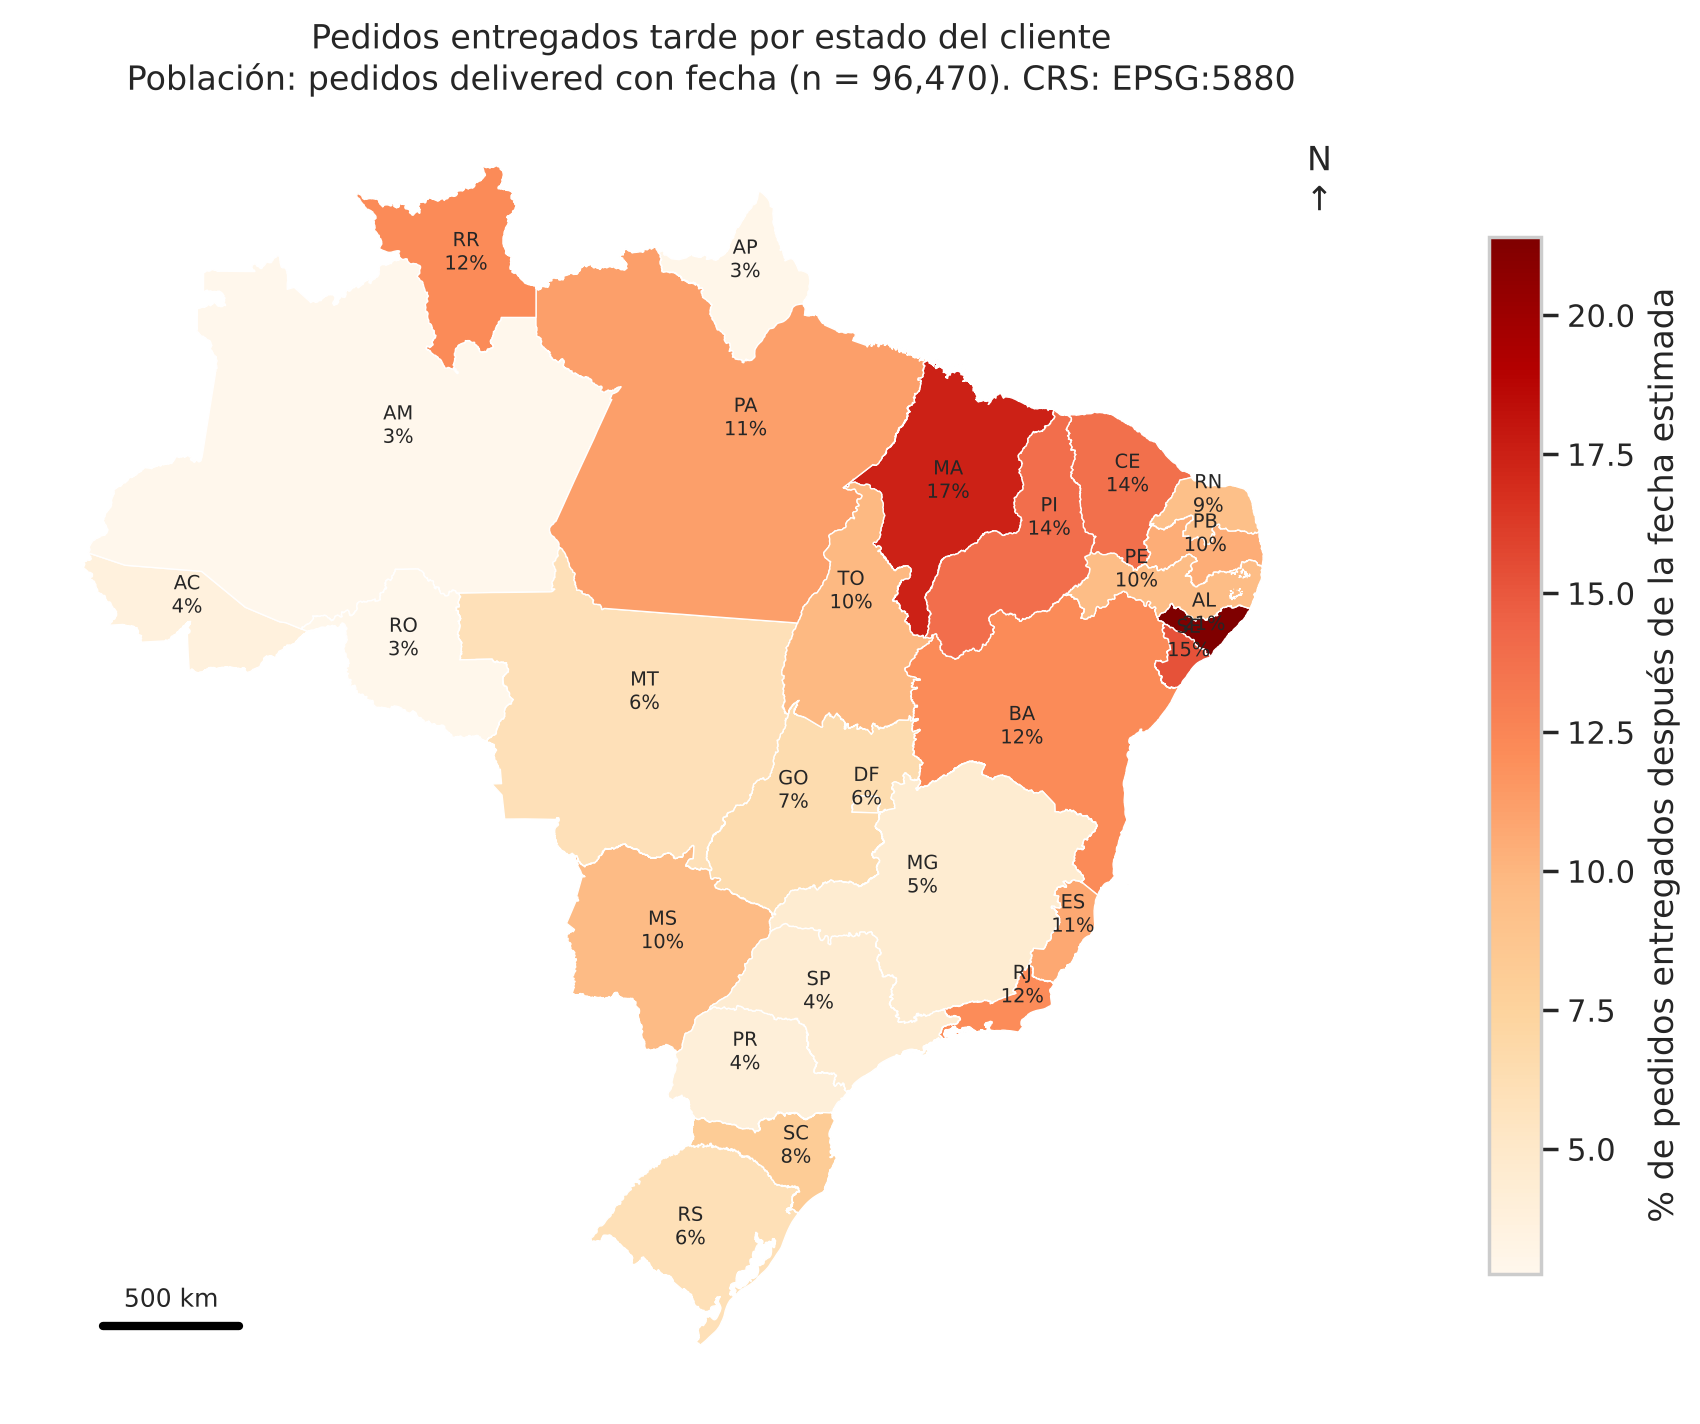

In [13]:
uf_poligonos = municipios.dissolve(by="uf_municipio", as_index=False)[["uf_municipio", "regiao", "geometry"]]
p1 = enriquecido[enriquecido["llego_tarde"].notna()].copy()
p1["llego_tarde"] = p1["llego_tarde"].astype(float)
por_uf = p1.groupby("customer_state").agg(pedidos=("order_id", "count"), pct_tarde=("llego_tarde", "mean"),
                                         distancia_mediana_km=("distancia_vendedor_km", "median"))
por_uf["pct_tarde"] *= 100
uf_poligonos = uf_poligonos.merge(por_uf, left_on="uf_municipio", right_index=True, how="left", validate="one_to_one")
uf_poligonos = uf_poligonos.to_crs(CRS_METRICO)


def barra_escala(ax, km=500):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x, y = x0 + (x1 - x0) * 0.06, y0 + (y1 - y0) * 0.06
    ax.plot([x, x + km * 1000], [y, y], color="black", lw=3)
    ax.text(x + km * 500, y + (y1 - y0) * 0.015, f"{km} km", ha="center", fontsize=9)
    ax.text(x1 - (x1 - x0) * 0.06, y1 - (y1 - y0) * 0.08, "N\n↑", ha="center", fontsize=12)
    ax.set_axis_off()


fig, ax = plt.subplots(figsize=(9, 9))
uf_poligonos.plot(column="pct_tarde", cmap="OrRd", legend=True, edgecolor="white", linewidth=0.5, ax=ax,
                  legend_kwds={"label": "% de pedidos entregados después de la fecha estimada", "shrink": 0.6})
for _, fila in uf_poligonos.iterrows():
    punto = fila.geometry.representative_point()
    ax.text(punto.x, punto.y, f"{fila['uf_municipio']}\n{fila['pct_tarde']:.0f}%", ha="center", fontsize=7)
barra_escala(ax)
ax.set_title(f"Pedidos entregados tarde por estado del cliente\nPoblación: pedidos delivered con fecha (n = {len(p1):,}). CRS: EPSG:5880")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "c2_03_mapa_tarde_uf.png", dpi=150)
plt.show()

**Interpretación:** el atraso tiene estructura geográfica clara. Los estados del nordeste (AL 21,4%, MA 17,4%, SE 15,2%, PI 13,9%, CE 13,8%) y RJ y ES en el sudeste (12,1% y 10,7%) duplican o triplican a SP (4,5%), PR (4,0%) y MG (4,6%). Los estados del norte con pocos pedidos (AM, AP, RO, AC) tienen porcentajes bajos, pero con menos de 250 pedidos cada uno y un intervalo de ±2 a ±4 puntos. **Decisión:** el mapa confirma P1; la pregunta siguiente es si esto es solo distancia.

### 5.2 Patrón combinado: ¿la distancia explica la geografía del atraso?

Si la región solo importara a través de la distancia, a igual distancia todas las regiones deberían atrasarse parecido.

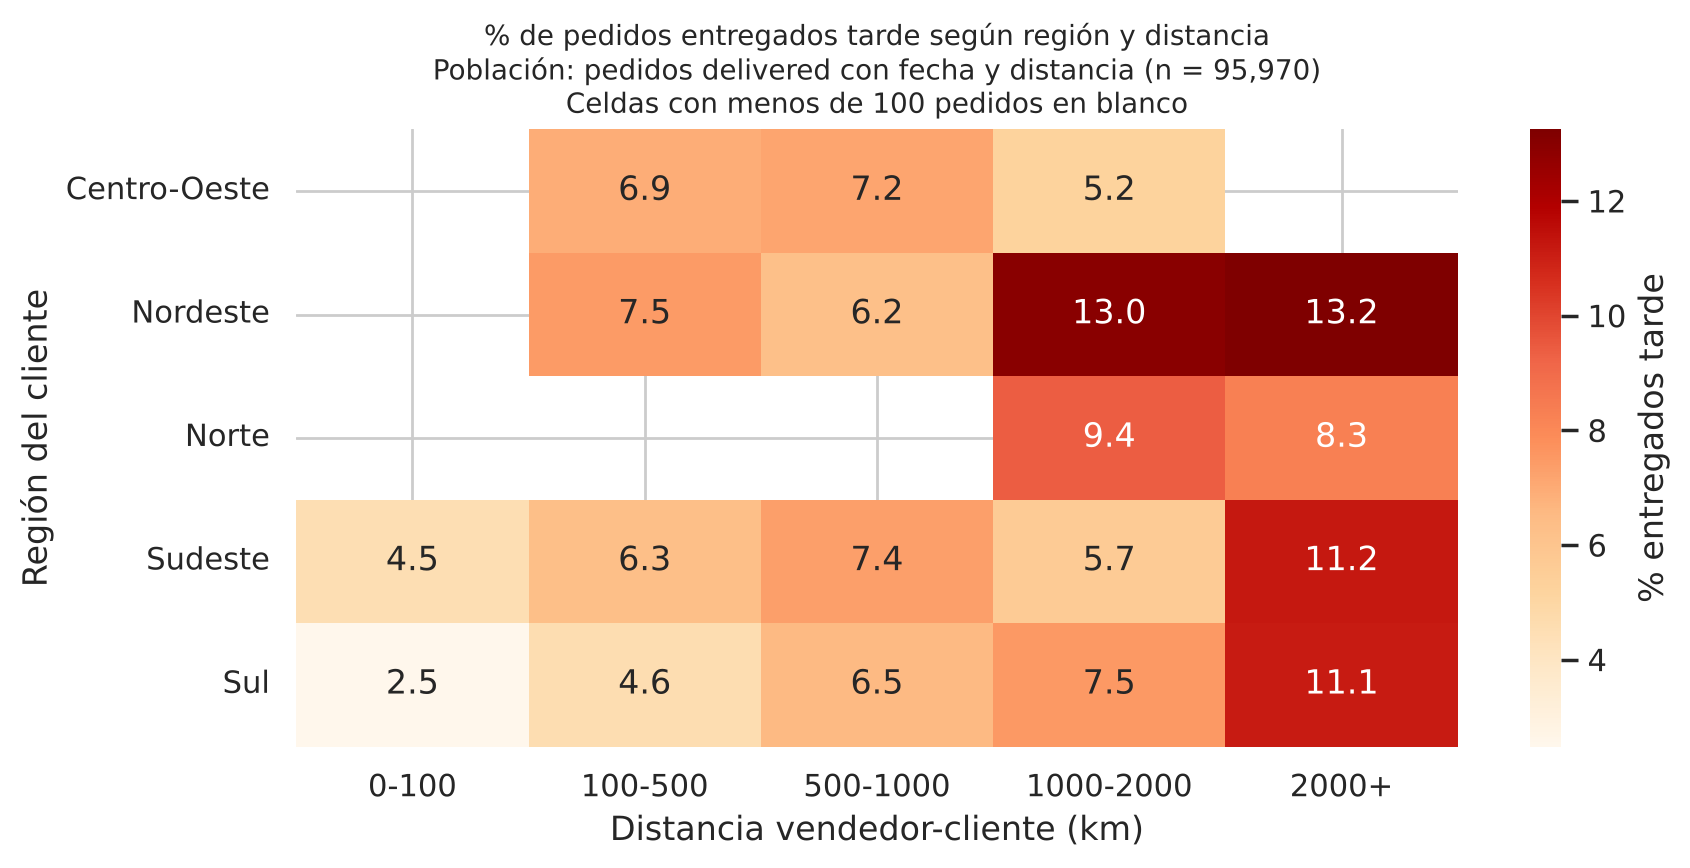

tramo_distancia,0-100,100-500,500-1000,1000-2000,2000+
region,,,,,
Centro-Oeste,75,290,3634,1411,28
Nordeste,80,107,401,4467,3941
Norte,0,4,24,446,1314
Sudeste,17076,31775,14968,1837,339
Sul,524,4636,6949,1518,126


In [14]:
p1 = p1.copy()
p1["tramo_distancia"] = pd.cut(p1["distancia_vendedor_km"], [0, 100, 500, 1000, 2000, 4500],
                               labels=["0-100", "100-500", "500-1000", "1000-2000", "2000+"])
cruce = p1.pivot_table(index="region", columns="tramo_distancia", values="llego_tarde", aggfunc="mean", observed=False) * 100
conteo = p1.pivot_table(index="region", columns="tramo_distancia", values="order_id", aggfunc="count", observed=False)
cruce = cruce.where(conteo >= 100)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(cruce, annot=True, fmt=".1f", cmap="OrRd", cbar_kws={"label": "% entregados tarde"}, ax=ax)
ax.set_xlabel("Distancia vendedor-cliente (km)")
ax.set_ylabel("Región del cliente")
ax.set_title(f"% de pedidos entregados tarde según región y distancia\nPoblación: pedidos delivered con fecha y distancia (n = {p1['tramo_distancia'].notna().sum():,})\nCeldas con menos de 100 pedidos en blanco", fontsize=10)
plt.tight_layout()
plt.savefig(RUTA_FIGS + "c2_04_region_distancia.png", dpi=150)
plt.show()
conteo

### 5.3 ¿Qué parte del atraso por estado no explican las variables tabulares?

Entrenamos un modelo solo con las features **no espaciales** y calculamos, por estado, la diferencia entre el porcentaje de atrasos observado y el esperado por el modelo (predicciones fuera de muestra con validación cruzada de 5 particiones). Un residuo positivo indica que en ese estado hay más atrasos de los que explican el plazo, el precio, el peso o la fecha.

AUC del modelo solo tabular: 0.727


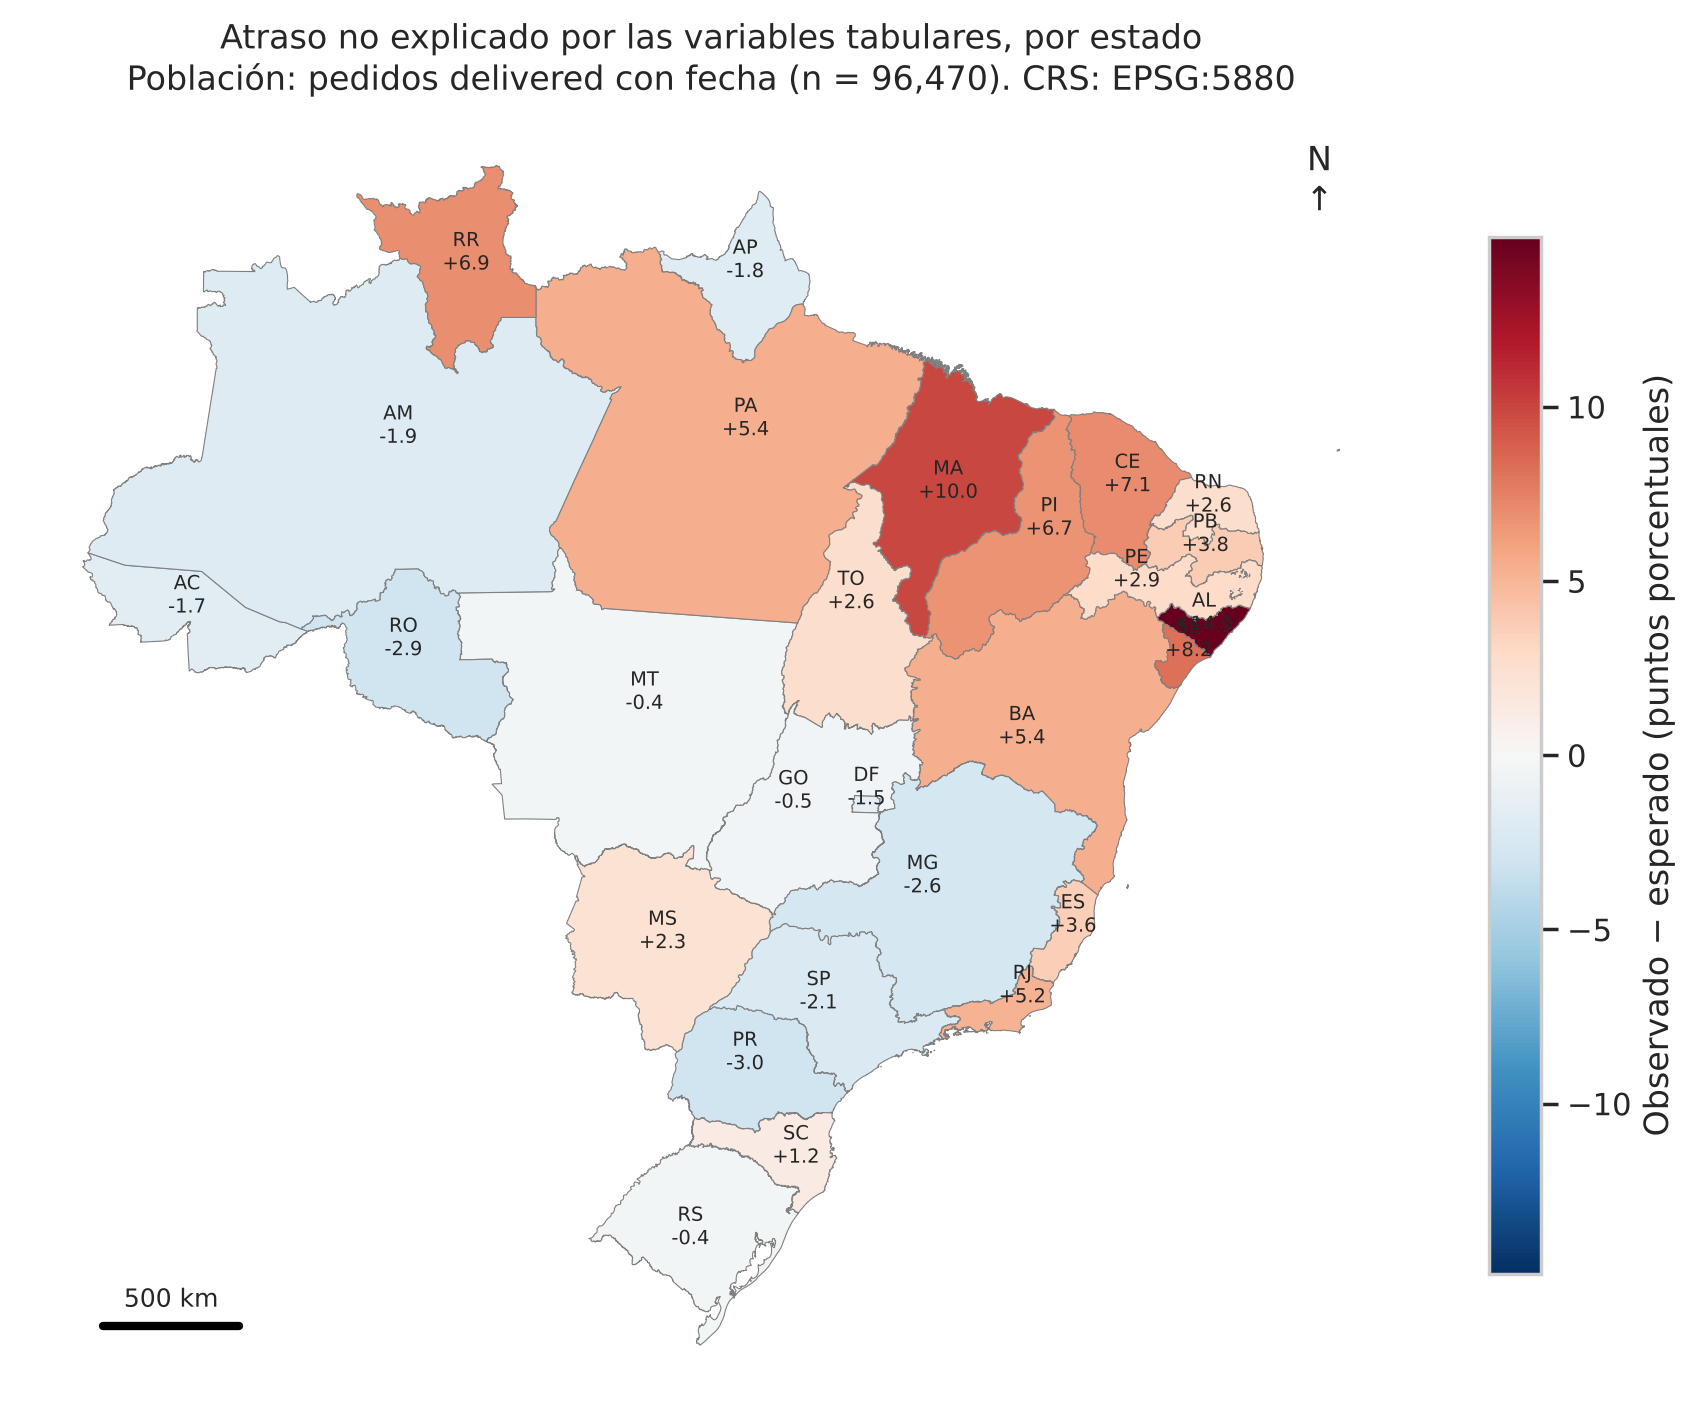

,pedidos,observado,esperado,residuo_pp,ic95_pp
customer_state,,,,,
AL,397,21.4,6.5,14.9,4.0
MA,717,17.4,7.5,10.0,2.8
SE,335,15.2,7.0,8.2,3.8
CE,1279,13.8,6.7,7.1,1.9
RR,41,12.2,5.3,6.9,10.0
PI,476,13.9,7.2,6.7,3.1
BA,3256,12.2,6.7,5.4,1.1
PA,946,11.2,5.8,5.4,2.0
RJ,12350,12.1,6.9,5.2,0.6


In [15]:
NO_ESPACIALES = ["ratio_flete_precio", "precio_medio_item", "n_items", "dias_prometidos", "horas_aprobacion",
                 "dia_semana", "hora_compra", "mes_compra", "compras_previas", "peso_total_kg"]
Xt = base[NO_ESPACIALES].astype(float)
Xt = Xt.fillna(Xt.median())
modelo_tabular = RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=50, n_jobs=-1, random_state=SEMILLA)
base["esperado"] = cross_val_predict(modelo_tabular, Xt, y, cv=5, method="predict_proba")[:, 1]
print(f"AUC del modelo solo tabular: {roc_auc_score(y, base['esperado']):.3f}")

residuo = base.groupby("customer_state").agg(pedidos=("order_id", "count"), observado=("llego_tarde", "mean"), esperado=("esperado", "mean"))
residuo[["observado", "esperado"]] *= 100
residuo["residuo_pp"] = residuo["observado"] - residuo["esperado"]
residuo["ic95_pp"] = 1.96 * np.sqrt(residuo["observado"] * (100 - residuo["observado"]) / residuo["pedidos"])
uf_poligonos = uf_poligonos.merge(residuo[["esperado", "residuo_pp", "ic95_pp"]], left_on="uf_municipio", right_index=True, how="left")

fig, ax = plt.subplots(figsize=(9, 9))
limite = uf_poligonos["residuo_pp"].abs().max()
uf_poligonos.plot(column="residuo_pp", cmap="RdBu_r", vmin=-limite, vmax=limite, legend=True, edgecolor="grey", linewidth=0.4, ax=ax,
                  legend_kwds={"label": "Observado − esperado (puntos porcentuales)", "shrink": 0.6})
for _, fila in uf_poligonos.iterrows():
    punto = fila.geometry.representative_point()
    ax.text(punto.x, punto.y, f"{fila['uf_municipio']}\n{fila['residuo_pp']:+.1f}", ha="center", fontsize=7)
barra_escala(ax)
ax.set_title("Atraso no explicado por las variables tabulares, por estado\n"
             f"Población: pedidos delivered con fecha (n = {len(base):,}). CRS: EPSG:5880")
plt.tight_layout()
plt.savefig(RUTA_FIGS + "c2_05_mapa_residuo_uf.png", dpi=150)
plt.show()
residuo.sort_values("residuo_pp", ascending=False).round(1)

**Interpretación:** el modelo solo tabular (AUC 0,727) espera un porcentaje de atrasos parecido en todos los estados, entre 4,7% y 7,5%. El atraso observado no se distribuye así: el residuo forma un bloque continuo en el nordeste (AL +14,9 puntos, MA +10,0, SE +8,2, CE +7,1, PI +6,7, BA +5,4) más RJ (+5,2 ± 0,6) y ES (+3,6). Del otro lado, SP, MG y PR tienen menos atrasos de los esperados (−2,1, −2,6 y −3,0). Este modelo no tiene la distancia, así que el residuo incluye su efecto; la celda siguiente la agrega. **Decisión:** las variables espaciales (UF o región, distancia, municipio) deben entrar en cualquier modelo de riesgo de atraso; un modelo tabular subestimaría sistemáticamente el riesgo en el nordeste y en RJ. **Qué no podemos concluir:** la causa. El dataset no registra la empresa de transporte ni la ruta, y RR, con 41 pedidos, tiene un intervalo de ±10 puntos.

In [16]:
tramo = p1[p1["distancia_vendedor_km"].between(100, 500, inclusive="right")]
print("Entre 100 y 500 km:")
print(tramo[tramo["customer_state"].isin(["RJ", "MG", "SP"])].groupby("customer_state")["llego_tarde"].agg(pedidos="count", pct_tarde="mean")
      .assign(pct_tarde=lambda d: (d["pct_tarde"] * 100).round(1)))

Xd = base[NO_ESPACIALES + ["distancia_vendedor_km"]].astype(float)
Xd = Xd.fillna(Xd.median())
base["esperado_con_distancia"] = cross_val_predict(modelo_tabular, Xd, y, cv=5, method="predict_proba")[:, 1]
residuo["residuo_con_distancia_pp"] = residuo["observado"] - base.groupby("customer_state")["esperado_con_distancia"].mean() * 100
residuo.sort_values("residuo_pp", ascending=False)[["pedidos", "observado", "residuo_pp", "residuo_con_distancia_pp"]].head(10).round(1)

Entre 100 y 500 km:
                pedidos  pct_tarde
customer_state                    
MG                 5561        5.3
RJ                 6658       12.0
SP                19376        4.7


,pedidos,observado,residuo_pp,residuo_con_distancia_pp
customer_state,,,,
AL,397,21.4,14.9,11.5
MA,717,17.4,10.0,5.4
SE,335,15.2,8.2,4.9
CE,1279,13.8,7.1,2.3
RR,41,12.2,6.9,5.0
PI,476,13.9,6.7,2.4
BA,3256,12.2,5.4,2.7
PA,946,11.2,5.4,2.6
RJ,12350,12.1,5.2,5.6


**Interpretación:** al agregar la distancia al modelo, el exceso del nordeste baja más o menos a la mitad: MA pasa de +10,0 a +5,4 puntos, CE de +7,1 a +2,3, PI de +6,7 a +2,4 y BA de +5,4 a +2,7. La distancia explica una parte importante. Pero AL (+11,5) y RJ (+5,6) casi no cambian. RJ es la evidencia más fuerte de un efecto regional: entre 100 y 500 km del vendedor, RJ tiene 12,0% de pedidos tarde contra 5,3% de MG y 4,7% de SP, con miles de pedidos en cada estado. En cambio, a más de 2.000 km el nordeste y el sudeste se parecen (13,2% contra 11,2%). **Decisión:** la respuesta a Q1 es que la distancia explica parte de la diferencia regional, no toda; queda un efecto geográfico claro en RJ y en AL. **Qué no podemos concluir:** la causa; el dataset no registra transportista ni ruta.

In [17]:
mun = (p1.groupby(["cod_municipio", "municipio", "customer_state", "es_capital"], observed=True)
         .agg(pedidos=("order_id", "count"), pct_tarde=("llego_tarde", "mean"), distancia_capital_km=("distancia_capital_km", "median"))
         .reset_index())
mun = mun[mun["pedidos"] >= 100]
mun["pct_tarde"] *= 100
print("Municipios con al menos 100 pedidos:", len(mun))
print(p1.groupby(["region", "es_capital"], observed=True)["llego_tarde"].agg(["count", "mean"]).assign(mean=lambda d: (d["mean"] * 100).round(1)))
mun.sort_values("pct_tarde", ascending=False).head(10).round(1)

Municipios con al menos 100 pedidos: 134
                         count  mean
region       es_capital             
Centro-Oeste False        2317   6.0
             True         3133   7.0
Nordeste     False        5115  10.7
             True         3901  15.3
Norte        False         864  10.2
             True          927   7.1
Sudeste      False       41431   5.9
             True        24720   6.4
Sul          False       10410   5.4
             True         3387   7.4


,cod_municipio,municipio,customer_state,es_capital,pedidos,pct_tarde,distancia_capital_km
884,2704302,Maceió,AL,True,236,27.1,4.3
2069,3300704,Cabo Frio,RJ,False,113,21.2,119.7
2130,3304904,São Gonçalo,RJ,False,375,21.1,20.8
295,2111300,São Luís,MA,True,335,19.4,5.4
2106,3303401,Nova Friburgo,RJ,False,145,19.3,98.4
379,2211001,Teresina,PI,True,269,19.0,4.8
2124,3304524,Rio das Ostras,RJ,False,130,17.7,138.1
2094,3302403,Macaé,RJ,False,231,16.9,157.3
2132,3305109,São João de Meriti,RJ,False,124,16.1,22.5
2120,3304201,Resende,RJ,False,120,15.8,138.6


**Interpretación:** dentro del nordeste, las capitales se atrasan **más** que el interior (15,3% contra 10,7%), al revés de lo que esperaríamos por cercanía al centro logístico. Maceió (27,1%), São Luís (19,4%) y Teresina (19,0%) encabezan los municipios con al menos 100 pedidos. En RJ, en cambio, los municipios con más atrasos son del interior y de la región metropolitana: Cabo Frio, São Gonçalo, Nova Friburgo, Macaé, São João de Meriti y Resende. **Qué no podemos concluir:** si se debe a la operación del transportista en esas ciudades, a promesas de entrega más ajustadas o a otro factor local; hace falta información de la ruta y del transportista.

## 6. Contraste con la predicción

| Predicción | ¿Se confirmó? | Evidencia |
|---|---|---|
| El plazo prometido explica buena parte de los atrasos | Parcial | 2.ª por permutación, pero 10.ª por información mutua: importa en combinación con otras variables, no sola |
| El flete relativo al precio es informativo | Parcial | 6.ª por información mutua, pero 13.ª por permutación: lo que aporta ya está en la distancia y el peso |
| Hora y día de compra no importan | Sí | Importancia nula con los dos métodos |
| La distancia vendedor-cliente importa | Sí | 4.ª por permutación (9.ª por información mutua); al sumarla al modelo, el exceso de atrasos de MA, CE y PI baja a la mitad o menos; dentro del sudeste, el atraso sube de 4,5% (menos de 100 km) a 11,2% (más de 2.000 km) |
| A igual distancia, las regiones se parecen | **No, en parte** | Entre 100 y 500 km, RJ tiene 12,0% tarde contra 5,3% de MG y 4,7% de SP; con la distancia en el modelo, AL y RJ siguen con +11,5 y +5,6 puntos. A más de 2.000 km, nordeste y sudeste sí se parecen (13,2% y 11,2%) |

Lo que no esperábamos: que la cercanía al Black Friday y el mes de compra fueran de lo más importante, y que las capitales del nordeste se atrasaran más que su interior.

## 7. Dataset enriquecido y controles

### 7.1 Esquema final

In [18]:
COLUMNAS_FINALES = [
    "order_id", "customer_unique_id", "customer_state", "region", "order_status", "order_purchase_timestamp",
    "order_estimated_delivery_date", "order_delivered_customer_date", "llego_tarde", "dias_vs_estimado", "review_score",
    "n_items", "total_precio", "total_flete", "n_vendedores", "ratio_flete_precio",
    "dias_prometidos", "horas_aprobacion", "dias_a_black_friday", "peso_total_kg", "tamano_pedido", "indice_envio_dificil", "distancia_vendedor_km", "mismo_estado",
    "cod_municipio", "municipio", "uf_municipio", "es_capital", "distancia_capital_km", "densidad_clientes_km2",
    "cliente_sin_coordenadas", "municipio_por_cercania", "uf_distinta", "sin_items", "en_periodo_mensual", "geometry",
]
final = enriquecido[COLUMNAS_FINALES].copy()
exigir_enriquecido(final)

Contrato del enriquecido OK: 99441 pedidos


In [19]:
final.to_parquet(RUTA_ENRICHED + "pedidos_enriquecidos.parquet", index=False)
para_gpkg = final.copy()
para_gpkg["tamano_pedido"] = para_gpkg["tamano_pedido"].astype(str).replace("nan", None)
for col in ["llego_tarde", "mismo_estado", "es_capital"]:
    para_gpkg[col] = para_gpkg[col].astype("float")
para_gpkg.to_file(RUTA_ENRICHED + "pedidos_enriquecidos.gpkg", layer="pedidos", driver="GPKG")
uf_poligonos.to_crs(CRS_GEOGRAFICO).to_file(RUTA_ENRICHED + "pedidos_enriquecidos.gpkg", layer="uf", driver="GPKG")
print({capa: len(gpd.read_file(RUTA_ENRICHED + "pedidos_enriquecidos.gpkg", layer=capa)) for capa in ["pedidos", "uf"]})
print(f"{os.path.getsize(RUTA_ENRICHED + 'pedidos_enriquecidos.gpkg') / 1e6:.1f} MB")

{'pedidos': 99441, 'uf': 27}
40.4 MB


**Esquema de `pedidos_enriquecidos`** (una fila por pedido, 99.441 filas, geometría = punto del cliente en EPSG:4326):

| Columnas | Qué representan | Origen |
|---|---|---|
| `order_id`, `customer_unique_id`, `customer_state`, `order_status`, fechas, `llego_tarde`, `dias_vs_estimado`, `review_score`, `n_items`, `total_precio`, `total_flete`, `n_vendedores`, `cliente_sin_coordenadas`, `sin_items`, `en_periodo_mensual` | identificación, resultado y marcas del pedido | producto curado del Caso 1 |
| `ratio_flete_precio`, `dias_prometidos`, `horas_aprobacion`, `dias_a_black_friday`, `peso_total_kg`, `tamano_pedido`, `indice_envio_dificil` | features derivadas que sobrevivieron | sección 4, a partir del curado |
| `distancia_vendedor_km`, `mismo_estado` | relación entre el vendedor y el cliente | coordenadas del Caso 1, EPSG:5880 |
| `cod_municipio`, `municipio`, `uf_municipio`, `municipio_por_cercania`, `uf_distinta` | municipio del cliente y calidad de la asignación | spatial join con la capa del IBGE (tbrugz/geodata-br) |
| `region`, `es_capital`, `distancia_capital_km`, `densidad_clientes_km2` | contexto regional y urbano | capas del IBGE (kelvins/municipios-brasileiros) y áreas en ESRI:102033 |

La capa `uf` del GeoPackage tiene un polígono por estado con pedidos, porcentaje de atrasos, distancia mediana, esperado por el modelo tabular y residuo.

### 7.2 Controles del enriquecido

Están en `src/contratos.py` (`schema_features`, `schema_espacial` y `validar_enriquecido`), además del contrato del Caso 1 que se corre al inicio.

| Control | Tipo | Qué exige |
|---|---|---|
| Rango de `ratio_flete_precio` | validez de features | entre 0 y 25, y nulo solo si el pedido no tiene ítems |
| Rangos de features temporales | validez de features | `dias_prometidos` entre 0 y 180; `horas_aprobacion` ≥ 0; día 0–6, hora 0–23; `dias_a_black_friday` 0–183 |
| `indice_envio_dificil` | validez de features | entre 0 y 1 |
| Todo pedido con coordenadas recibe municipio | integridad espacial | `cod_municipio` nulo ⇔ `cliente_sin_coordenadas` |
| Coherencia del spatial join | integridad espacial | `uf_distinta` recalculado igual, y como mucho 0,1% de pedidos con municipio de otra UF o asignados por cercanía |
| Distancias plausibles | integridad espacial | `distancia_vendedor_km` entre 0 y 4.500 km y mediana > 100 km (detecta cálculo en grados o en metros) |
| CRS y ubicación | integridad espacial | CRS EPSG:4326 y todos los puntos dentro de Brasil |

## 8. Desafío del pipeline completo

Cada escenario modifica el **producto curado o una capa** y corre el pipeline entero: primero el contrato del Caso 1, después `enriquecer` y después los controles nuevos.

In [20]:
def correr(nombre, regla, pedidos_mod=None, items_mod=None, municipios_mod=None, crs_metrico=CRS_METRICO):
    ped = pedidos_mod(pedidos.copy()) if pedidos_mod else pedidos
    its = items_mod(items.copy()) if items_mod else items
    mun = municipios_mod(municipios.copy()) if municipios_mod else municipios
    try:
        exigir(ped, its, n_orders=99441)
        caso1 = "pasa"
    except ValueError:
        caso1 = "falla"
    fallas = validar_enriquecido(enriquecer(ped, its, mun, capitales, crs_metrico=crs_metrico))
    return {"escenario": nombre, "regla que se viola": regla, "contrato Caso 1": caso1,
            "controles nuevos": "falla" if len(fallas) else "pasa",
            "qué falló": "; ".join(sorted(set(fallas["control"].str.slice(0, 70)))) if len(fallas) else "-"}


def precio_casi_cero(df):
    idx = df.index[df["n_items"] > 0][:20]
    df.loc[idx, "total_precio"] = 0.01
    return df


def estimada_antes_de_compra(df):
    df.loc[df.index[:20], "order_estimated_delivery_date"] = df.loc[df.index[:20], "order_purchase_timestamp"] - pd.Timedelta(days=3)
    return df


def sin_municipios_de_sp(df):
    return df[df["uf_municipio"] != "SP"]


def clientes_movidos_a_otro_estado(df):
    idx = df.index[(df["customer_state"] == "SP") & df["cliente_lat"].notna()][:500]
    df.loc[idx, ["cliente_lat", "cliente_lng"]] = [-12.97, -38.50]
    return df


def cliente_movido_dentro_del_estado(df):
    idx = df.index[(df["customer_state"] == "SP") & df["cliente_lat"].notna()][:50]
    df.loc[idx, ["cliente_lat", "cliente_lng"]] = [-22.90, -47.06]
    return df


resultado = pd.DataFrame([
    correr("total_precio de 0,01 BRL en 20 pedidos", "ratio_flete_precio <= 25", pedidos_mod=precio_casi_cero),
    correr("fecha estimada 3 días antes de la compra", "dias_prometidos >= 0", pedidos_mod=estimada_antes_de_compra),
    correr("capa municipal sin SP", "todo pedido con coordenadas recibe municipio", municipios_mod=sin_municipios_de_sp),
    correr("500 clientes de SP con coordenadas de Salvador", "municipio de otra UF <= 0,1%", pedidos_mod=clientes_movidos_a_otro_estado),
    correr("distancias calculadas en grados (EPSG:4326)", "distancias en km plausibles", crs_metrico=CRS_GEOGRAFICO),
    correr("50 clientes de SP movidos a Campinas", "ninguna (ubicación válida pero falsa)", pedidos_mod=cliente_movido_dentro_del_estado),
])
resultado.to_csv(RUTA_REPORTS + "desafio_enriquecido.csv", index=False)
resultado

Contrato OK: 99441 pedidos y 112650 ítems


Contrato OK: 99441 pedidos y 112650 ítems


Contrato OK: 99441 pedidos y 112650 ítems


Contrato OK: 99441 pedidos y 112650 ítems


Contrato OK: 99441 pedidos y 112650 ítems


/tmp/ipykernel_174/2326729678.py:36: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  vendedores["distancia_km"] = vendedores.geometry.distance(gpd.GeoSeries(cliente_de_item, crs=crs_metrico, index=vendedores.index)) / 1000


/usr/local/lib/python3.13/site-packages/geopandas/array.py:438: UserWarning: Geometry is in a geographic CRS. Results from 'sjoin_nearest' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  warnings.warn(


/tmp/ipykernel_174/2326729678.py:65: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  df["distancia_capital_km"] = clientes.geometry.distance(destino) / 1000


Contrato OK: 99441 pedidos y 112650 ítems


,escenario,regla que se viola,contrato Caso 1,controles nuevos,qué falló
0,"total_precio de 0,01 BRL en 20 pedidos",ratio_flete_precio <= 25,pasa,falla,"in_range(0, 25)"
1,fecha estimada 3 días antes de la compra,dias_prometidos >= 0,pasa,falla,"in_range(0, 180)"
2,capa municipal sin SP,todo pedido con coordenadas recibe municipio,pasa,falla,pedidos asignados por cercanía <= 0.1%; pedido...
3,500 clientes de SP con coordenadas de Salvador,"municipio de otra UF <= 0,1%",pasa,falla,pedidos con municipio de otra UF <= 0.1%
4,distancias calculadas en grados (EPSG:4326),distancias en km plausibles,pasa,falla,mediana de distancia vendedor-cliente > 100 km...
5,50 clientes de SP movidos a Campinas,ninguna (ubicación válida pero falsa),pasa,pasa,-


**Interpretación:** en los cinco escenarios que violan una regla nueva, el contrato del Caso 1 **pasa** y los controles del enriquecido **fallan**. Eso muestra que son necesarios: el curado puede estar sano y el enriquecimiento romperse igual.

- **`total_precio` de 0,01 BRL:** dispara el rango de `ratio_flete_precio`. También revela un hueco del Caso 1: su contrato no comprueba que `total_precio` coincida con la suma de los ítems.
- **Fecha estimada antes de la compra:** la detecta el rango de `dias_prometidos`. El Caso 1 no la ve porque cada fecha por separado es válida.
- **Capa municipal sin SP:** simula una capa externa incompleta. Deja sin municipio a todos los clientes de SP y la detectan tres controles a la vez: la cobertura del spatial join, el umbral de asignación por cercanía y el de municipios de otra UF (los clientes de SP cercanos a la frontera quedan asignados a municipios vecinos).
- **500 clientes de SP con coordenadas de Salvador:** coordenadas válidas pero incoherentes con la UF. Las detecta el umbral de 0,1% de municipios de otra UF. Con 30 clientes movidos no se habría detectado: el control es estadístico, no fila por fila.
- **Distancias en grados:** dan valores entre 0 y 0,03 (grados divididos por 1000) que pasan el rango de 0 a 4.500. Las detecta la regla de la mediana mayor a 100 km; sin ella, este error habría pasado.
- **50 clientes de SP movidos a Campinas:** **no** se detecta. La ubicación es válida, dentro de su UF y en un municipio real; ningún control puede distinguirla sin una fuente externa de direcciones.

## 9. Conclusiones

**Qué habilita el dataset enriquecido que el original no:**

- Analizar qué variables disponibles al momento de la compra se asocian al atraso, con contexto espacial: con la misma validación cruzada, las features espaciales suben el AUC de 0,740 a 0,778.
- Analizar rutas (estado del vendedor → municipio del cliente) y distancias reales en km.
- Bajar el análisis de P1 de estado a municipio: 134 municipios tienen al menos 100 pedidos.
- Mapas y agregaciones espaciales, y separar el efecto de la distancia del efecto de la región.

**Limitaciones que introduce el enriquecimiento:**

- Las coordenadas son la mediana del prefijo de CEP, no la dirección: sirven para distancias entre ciudades, no dentro de una ciudad.
- 279 pedidos no tienen coordenadas y 1.265 no tienen distancia al vendedor; 48 recibieron municipio por cercanía y 34 caen en un municipio de otra UF.
- La malla municipal tiene 5.564 municipios, anterior a la creación de los 6 más nuevos.
- Por alcance no incorporamos población; queda como paso siguiente. Por eso `densidad_clientes_km2` mide clientes de Olist, no habitantes.
- Los AUC salen de un split aleatorio. Con un corte temporal bajan a 0,636 con espaciales y 0,597 sin ellas: el modelo describe mejor de lo que anticipa.
- `dias_a_black_friday` en la práctica ve un solo Black Friday (2017).
- Sesgo geográfico: SP concentra el 42% de los pedidos, y los estados del norte tienen muestras chicas.
- Las importancias son predictivas, no causales.

**Pasos para llevarlo a producción:**

- Fijar las capas externas a un commit o versión y guardar su hash. Hoy se bajan de la rama principal de dos repositorios de GitHub, que pueden cambiar.
- Versionar curado y enriquecido (por ejemplo con DVC) y correr los dos contratos en un pipeline orquestado, con alertas cuando un control falle.
- Agregar al contrato del Caso 1 el control que faltó en el desafío: que `total_precio` coincida con la suma de los precios de sus ítems.
- Incorporar población y datos socioeconómicos del IBGE por municipio.
- Monitorear la deriva de los umbrales (% de `uf_distinta`, % por cercanía, mediana de distancias) con datos nuevos.

## 10. Uso de IA

Secuencia del curso: predecir, intentar, consultar, verificar y declarar. No se compartieron con la IA datos sensibles, credenciales ni información personal.

| Fecha | Integrante | Herramienta | Para qué | Qué produjo | Qué modificamos | Cómo lo validamos |
|---|---|---|---|---|---|---|
| 22-11 | Juan Pablo Esteva | Claude (Opus 5.5) | Implementar el pipeline de enriquecimiento, los controles y el desafío | Este notebook y los contratos del enriquecido en `src/contratos.py` | Verificamos lo que nos dio la IA (código, features y umbrales de los controles) y nos pareció correcto, así que lo mantuvimos como estaba. | El notebook se ejecutó de principio a fin al generarlo. El 22-11 se volvió a correr con Claude en un entorno limpio (clon nuevo, Python 3.12, `requirements.txt` desde cero, capas del IBGE descargadas por el notebook) y dio los mismos resultados: 48 pedidos asignados por cercanía, 279 sin municipio y 34 con municipio de otra UF; AUC 0,781; contrato del enriquecido OK con 99.441 pedidos; desafío con 5 escenarios que fallan y el último que pasa. Además se revisó el CRS de cada cálculo (distancias y spatial joins en EPSG:5880, áreas en ESRI:102033; EPSG:4326 solo en el escenario del desafío que lo usa a propósito), se chequeó SP–Salvador (1.470 km en EPSG:5880 contra 1.452 km de distancia geodésica), se abrió el `.gpkg` con geopandas (capa `pedidos` con 99.441 filas y capa `uf` con 27) y se cotejaron los números del informe con las salidas (por ejemplo, los 8.579 pedidos sin municipio si no se aplica `make_valid`, recalculados aparte). |
| 22-11 | Ivan Lomando | Claude (Opus 5.5) | Verificar que el notebook corra en un entorno limpio, cotejar los números del informe y completar esta declaración a partir del historial de los archivos | Re-ejecución comparada con los valores esperados y el texto de las columnas "Qué modificamos" y "Cómo lo validamos" de la fila anterior | Sin cambios en el código ni en los resultados; solo se completó esta tabla | Se comparó la re-ejecución con los valores esperados (coinciden todos) y la versión generada por la IA con la subida a GitHub (solo cambió la URL del repositorio) |
| 22-11 | Juan Pablo Esteva | Claude (Opus 5.5) | Aplicar las 10 correcciones de la revisión de Bruno Fidalgo: bug de `es_capital` (comparar por código IBGE), AUC comparables con la misma validación cruzada, corte temporal, residuo con distancia, licencia CC0 de la capa municipal y ajustes de texto | Celdas nuevas en 4.3 y 5.3, corrección de `enriquecer` y textos de interpretación | Las correcciones siguen las indicaciones de Bruno, que revisó la entrega y detectó los errores | Bruno recalculó por su cuenta AUC 0,778 / 0,740, los 27 pedidos mal marcados como capital y los residuos con distancia; coinciden con el notebook vuelto a ejecutar |